# Exercice 3 — Implémenter un mini-BERT pour retrouver des mots masqués

**Objectif :** entraîner un Transformer **bidirectionnel** à reconstruire des mots masqués grâce au contexte
situé **à gauche et à droite** (modélisation du langage masqué, *MLM*).

- Tokenisation par mots, séquences de 32 tokens : `[CLS] le chat dort sur le canapé [SEP] [PAD] ...`
- 15 % des tokens ordinaires sélectionnés : 80 % → `[MASK]`, 10 % → mot aléatoire, 10 % inchangés
- Embeddings tokens + positions (dim 64), 2 couches encodeur à 4 têtes, **sans masque causal**, avec masque de padding
- Perte calculée **uniquement** sur les positions sélectionnées

In [1]:
import random
import itertools

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

random.seed(42)
torch.manual_seed(42)

PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4
SPECIAUX = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]
LONGUEUR = 32

## 1. Un petit corpus de phrases

Le corpus est généré à partir de gabarits, de sorte que plusieurs mots ne peuvent être retrouvés
**qu'en regardant à droite** (par ex. l'animal se déduit du verbe qui le suit : *le [MASK] aboie* → *chien*).

In [2]:
animaux = [  # (déterminant, animal, cri, nourriture)
    ("le", "chat", "miaule", "du poisson"),
    ("le", "chien", "aboie", "des croquettes"),
    ("la", "vache", "meugle", "de l'herbe"),
    ("le", "cheval", "hennit", "du foin"),
    ("la", "poule", "caquette", "du grain"),
    ("le", "mouton", "bêle", "de la paille"),
]
lieux = ["dans le jardin", "dans la cuisine", "sur le canapé", "près de la maison", "dans la ferme", "sous la table"]
moments = ["le matin", "le soir", "la nuit", "à midi"]

personnes = [  # (sujet, action, lieu associé)
    ("l'étudiant", "lit un livre", "à la bibliothèque"),
    ("le professeur", "explique la leçon", "dans la classe"),
    ("le médecin", "soigne un patient", "à l'hôpital"),
    ("le boulanger", "prépare le pain", "à la boulangerie"),
    ("le pêcheur", "attrape un poisson", "au port"),
    ("l'ingénieur", "entraîne un modèle", "au laboratoire"),
]

faits = [
    "rabat est la capitale du maroc",
    "casablanca est la plus grande ville du maroc",
    "marrakech est une ville rouge du maroc",
    "le soleil se lève à l'est",
    "le soleil se couche à l'ouest",
    "la neige tombe sur les montagnes de l'atlas en hiver",
    "il fait chaud en été et froid en hiver",
]

phrases = []
for (det, a, cri, food), lieu, moment in itertools.product(animaux, lieux, moments):
    phrases.append(f"{det} {a} {cri} {lieu} {moment}")
    phrases.append(f"{det} {a} dort {lieu} {moment}")
for (det, a, cri, food), lieu in itertools.product(animaux, lieux):
    phrases.append(f"{det} {a} mange {food} {lieu}")
for (sujet, action, lieu), moment in itertools.product(personnes, moments):
    phrases.append(f"{sujet} {action} {lieu} {moment}")
phrases += faits * 6   # répéter les faits pour qu'ils soient vus assez souvent

random.shuffle(phrases)
coupure = int(0.85 * len(phrases))
phrases_train, phrases_val = phrases[:coupure], phrases[coupure:]

print("Phrases :", len(phrases), "| train :", len(phrases_train), "| validation :", len(phrases_val))
for p in phrases_train[:5]:
    print("  ", p)

Phrases : 390 | train : 331 | validation : 59
   l'ingénieur entraîne un modèle au laboratoire le matin
   le cheval mange du foin dans le jardin
   casablanca est la plus grande ville du maroc
   le mouton bêle dans le jardin le matin
   le chien aboie près de la maison le matin


## 2. Vocabulaire, encodage et padding à 32 tokens

Le vocabulaire est construit **uniquement sur le corpus d'entraînement** ; un mot inconnu devient `[UNK]`.

In [3]:
mots = sorted({m for p in phrases_train for m in p.split()})
itos = SPECIAUX + mots
stoi = {m: i for i, m in enumerate(itos)}
taille_vocabulaire = len(itos)
print("Taille du vocabulaire :", taille_vocabulaire)


def encoder(phrase):
    ids = [CLS] + [stoi.get(m, UNK) for m in phrase.split()] + [SEP]
    ids = ids[:LONGUEUR]
    return ids + [PAD] * (LONGUEUR - len(ids))


def decoder(ids):
    return " ".join(itos[i] for i in ids)


train_ids = torch.tensor([encoder(p) for p in phrases_train])
val_ids = torch.tensor([encoder(p) for p in phrases_val])

print("train_ids :", tuple(train_ids.shape), "| val_ids :", tuple(val_ids.shape))
print(decoder(train_ids[0].tolist()))

Taille du vocabulaire : 100
train_ids : (331, 32) | val_ids : (59, 32)
[CLS] l'ingénieur entraîne un modèle au laboratoire le matin [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


## 3. Masquage 15 % (80 % `[MASK]` / 10 % aléatoire / 10 % inchangé)

In [4]:
def masquer(input_ids, proba=0.15, generateur=None):
    """Retourne (ids corrompus, positions sélectionnées). Les tokens spéciaux ne sont jamais sélectionnés."""
    ordinaires = input_ids >= len(SPECIAUX)
    tirage = torch.rand(input_ids.shape, generator=generateur)
    selection = (tirage < proba) & ordinaires

    # Au moins une position sélectionnée par phrase contenant des tokens ordinaires
    for i in range(len(input_ids)):
        if not selection[i].any() and ordinaires[i].any():
            candidats = ordinaires[i].nonzero(as_tuple=True)[0]
            j = candidats[torch.randint(len(candidats), (1,), generator=generateur)]
            selection[i, j] = True

    corrompus = input_ids.clone()
    choix = torch.rand(input_ids.shape, generator=generateur)
    vers_mask = selection & (choix < 0.8)
    vers_aleatoire = selection & (choix >= 0.8) & (choix < 0.9)
    # les 10 % restants (choix >= 0.9) restent inchangés
    corrompus[vers_mask] = MASK
    aleatoires = torch.randint(len(SPECIAUX), taille_vocabulaire, input_ids.shape, generator=generateur)
    corrompus[vers_aleatoire] = aleatoires[vers_aleatoire]
    return corrompus, selection


g = torch.Generator().manual_seed(0)
c, s = masquer(train_ids[:3], generateur=g)
for i in range(3):
    print("original :", decoder([t for t in train_ids[i].tolist() if t != PAD]))
    print("corrompu :", decoder([t for t in c[i].tolist() if t != PAD]))
    print("à prédire:", [itos[t] for t in train_ids[i][s[i]].tolist()])
    print()

original : [CLS] l'ingénieur entraîne un modèle au laboratoire le matin [SEP]
corrompu : [CLS] l'ingénieur [MASK] [MASK] modèle au laboratoire le matin [SEP]
à prédire: ['entraîne', 'un']

original : [CLS] le cheval mange du foin dans le jardin [SEP]
corrompu : [CLS] le cheval [MASK] du foin dans le jardin [SEP]
à prédire: ['mange']

original : [CLS] casablanca est la plus grande ville du maroc [SEP]
corrompu : [CLS] casablanca est la plus grande [MASK] du maroc [SEP]
à prédire: ['ville']



In [5]:
# Vérification des proportions sur un grand tirage
g = torch.Generator().manual_seed(1)
grand = train_ids.repeat(20, 1)
c, s = masquer(grand, generateur=g)
ordinaires = grand >= len(SPECIAUX)
print(f"Tokens ordinaires sélectionnés : {s.sum() / ordinaires.sum():.1%}  (≈15 %, un peu plus à cause du minimum 1/phrase)")
print(f"  -> [MASK]     : {(c[s] == MASK).float().mean():.1%}")
print(f"  -> inchangés  : {(c[s] == grand[s]).float().mean():.1%}  (≈10 % + tirages aléatoires tombés sur le même mot)")
print(f"  -> aléatoires : {((c[s] != MASK) & (c[s] != grand[s])).float().mean():.1%}")
print("Tokens spéciaux jamais sélectionnés :", not s[~ordinaires].any().item())

Tokens ordinaires sélectionnés : 18.1%  (≈15 %, un peu plus à cause du minimum 1/phrase)
  -> [MASK]     : 80.2%
  -> inchangés  : 9.9%  (≈10 % + tirages aléatoires tombés sur le même mot)
  -> aléatoires : 10.0%
Tokens spéciaux jamais sélectionnés : True


## 4. Le modèle mini-BERT

In [6]:
class MiniBERT(nn.Module):
    def __init__(self, taille_vocabulaire, longueur=LONGUEUR, d_model=64, nhead=4, n_couches=2, dropout=0.1):
        super().__init__()
        self.tok_emb = nn.Embedding(taille_vocabulaire, d_model, padding_idx=PAD)
        self.pos_emb = nn.Embedding(longueur, d_model)
        self.norm = nn.LayerNorm(d_model)
        couche = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=4 * d_model,
            dropout=dropout, activation="gelu", batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=n_couches, enable_nested_tensor=False)
        self.tete = nn.Linear(d_model, taille_vocabulaire)   # projection vers le vocabulaire

    def forward(self, ids):
        pos = torch.arange(ids.size(1), device=ids.device)
        x = self.norm(self.tok_emb(ids) + self.pos_emb(pos))
        masque_padding = ids == PAD             # True = position de padding ignorée
        # Pas de masque causal : attention bidirectionnelle
        x = self.encodeur(x, src_key_padding_mask=masque_padding)
        return self.tete(x)                     # (B, 32, vocabulaire)


modele = MiniBERT(taille_vocabulaire)
print("Paramètres :", sum(p.numel() for p in modele.parameters()))
print("Logits :", tuple(modele(train_ids[:4]).shape))

Paramètres : 115044


Logits : (4, 32, 100)


## 5. Entraînement — perte uniquement sur les positions sélectionnées

In [7]:
critere = nn.CrossEntropyLoss(ignore_index=-100)


def perte_mlm(modele, input_ids, generateur=None):
    corrompus, positions_selectionnees = masquer(input_ids, generateur=generateur)
    labels = input_ids.clone()
    labels[~positions_selectionnees] = -100          # ignorer les positions non sélectionnées
    logits = modele(corrompus)
    loss = critere(logits.reshape(-1, taille_vocabulaire), labels.reshape(-1))
    return loss, logits, labels


@torch.no_grad()
def evaluer(modele, ids, graine=123):
    """Masquage fixe (même graine) pour comparer les époques. Exactitude sur les tokens sélectionnés."""
    modele.eval()
    g = torch.Generator().manual_seed(graine)
    loss, logits, labels = perte_mlm(modele, ids, generateur=g)
    sel = labels != -100
    exactitude = (logits.argmax(-1)[sel] == labels[sel]).float().mean().item()
    modele.train()
    return loss.item(), exactitude


torch.manual_seed(42)
modele = MiniBERT(taille_vocabulaire)
optimiseur = torch.optim.AdamW(modele.parameters(), lr=1e-3, weight_decay=0.01)
historique = {"train": [], "val": [], "acc": []}

modele.train()
for epoch in range(1, 81):
    ordre = torch.randperm(len(train_ids))
    total = 0.0
    for k in range(0, len(ordre), 32):
        batch = train_ids[ordre[k:k + 32]]
        loss, _, _ = perte_mlm(modele, batch)      # masquage dynamique : nouveau tirage à chaque époque
        optimiseur.zero_grad()
        loss.backward()
        optimiseur.step()
        total += loss.item() * len(batch)
    perte_val, acc_val = evaluer(modele, val_ids)
    historique["train"].append(total / len(train_ids))
    historique["val"].append(perte_val)
    historique["acc"].append(acc_val)
    if epoch % 10 == 0:
        print(f"Epoch {epoch:2d} | train {total / len(train_ids):.3f} | val {perte_val:.3f} | exactitude val {acc_val:.1%}")

Epoch 10 | train 2.014 | val 1.956 | exactitude val 47.8%


Epoch 20 | train 1.104 | val 1.265 | exactitude val 63.0%


Epoch 30 | train 0.847 | val 0.829 | exactitude val 72.8%


Epoch 40 | train 0.571 | val 0.811 | exactitude val 70.7%


Epoch 50 | train 0.614 | val 0.626 | exactitude val 75.0%


Epoch 60 | train 0.404 | val 0.491 | exactitude val 82.6%


Epoch 70 | train 0.415 | val 0.494 | exactitude val 80.4%


Epoch 80 | train 0.413 | val 0.370 | exactitude val 81.5%


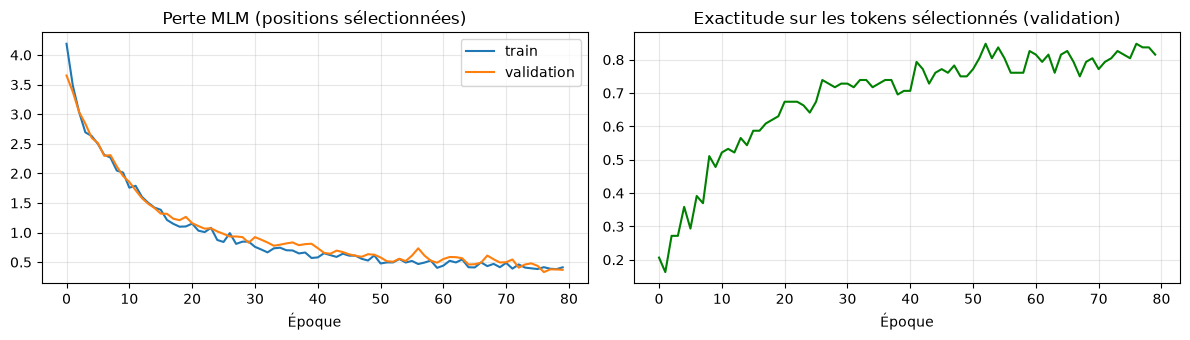

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(historique["train"], label="train")
axes[0].plot(historique["val"], label="validation")
axes[0].set_title("Perte MLM (positions sélectionnées)")
axes[0].legend()
axes[1].plot(historique["acc"], color="green")
axes[1].set_title("Exactitude sur les tokens sélectionnés (validation)")
for ax in axes:
    ax.set_xlabel("Époque")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Exactitude finale et top-3 pour quelques mots masqués

In [9]:
# Moyenne sur plusieurs tirages de masquage pour une mesure plus stable
scores = [evaluer(modele, val_ids, graine=s)[1] for s in range(10)]
print(f"Exactitude sur les tokens sélectionnés (validation, 10 tirages) : {sum(scores) / len(scores):.1%}")

Exactitude sur les tokens sélectionnés (validation, 10 tirages) : 83.2%


In [10]:
@torch.no_grad()
def top3(phrase):
    """phrase contient un ou plusieurs [MASK]."""
    modele.eval()
    ids = [CLS] + [MASK if m == "[MASK]" else stoi.get(m, UNK) for m in phrase.split()] + [SEP]
    ids = torch.tensor([ids + [PAD] * (LONGUEUR - len(ids))])
    probas = modele(ids).softmax(-1)[0]
    resultats = []
    for pos in (ids[0] == MASK).nonzero(as_tuple=True)[0]:
        top = torch.topk(probas[pos], 3)
        resultats.append(", ".join(f"{itos[i]} ({p:.0%})" for p, i in zip(top.values.tolist(), top.indices.tolist())))
    return resultats


exemples = [
    "le [MASK] aboie dans le jardin le soir",     # animal déduit du verbe à DROITE
    "le [MASK] miaule sur le canapé la nuit",
    "la vache [MASK] près de la maison le matin",
    "le cheval mange [MASK] foin dans la ferme",
    "rabat est la [MASK] du maroc",
    "le soleil se couche à [MASK]",                # « l'ouest » est un seul token (découpage par espaces)
    "le médecin soigne un patient [MASK] l'hôpital le soir",
    "[MASK] chien dort sous la table à midi",
]
for e in exemples:
    print(f"{e:<50} -> {' | '.join(top3(e))}")

le [MASK] aboie dans le jardin le soir             -> chien (96%), chat (1%), cheval (1%)
le [MASK] miaule sur le canapé la nuit             -> chat (93%), le (2%), cheval (1%)
la vache [MASK] près de la maison le matin         -> meugle (88%), dort (7%), caquette (1%)
le cheval mange [MASK] foin dans la ferme          -> du (93%), de (2%), des (1%)
rabat est la [MASK] du maroc                       -> capitale (95%), ville (1%), plus (1%)
le soleil se couche à [MASK]                       -> l'ouest (95%), couche (1%), jardin (1%)
le médecin soigne un patient [MASK] l'hôpital le soir -> à (98%), au (1%), dans (0%)
[MASK] chien dort sous la table à midi             -> le (99%), la (1%), midi (0%)


Exemples tirés du jeu de **validation** (phrases jamais vues à l'entraînement) :

In [11]:
g = torch.Generator().manual_seed(7)
corrompus, sel = masquer(val_ids[:6], generateur=g)
modele.eval()
with torch.no_grad():
    probas = modele(corrompus).softmax(-1)
for i in range(6):
    phrase = decoder([t for t in corrompus[i].tolist() if t != PAD][1:-1])
    print("Entrée :", phrase)
    for pos in sel[i].nonzero(as_tuple=True)[0]:
        top = torch.topk(probas[i, pos], 3)
        props = ", ".join(f"{itos[j]} ({p:.0%})" for p, j in zip(top.values.tolist(), top.indices.tolist()))
        print(f"   position {pos.item():2d} | attendu « {itos[val_ids[i, pos]]} » -> {props}")

Entrée : la poule mange du grain dans la [MASK]
   position  8 | attendu « ferme » -> ferme (50%), cuisine (48%), jardin (1%)
Entrée : le mouton mange de la paille près [MASK] la maison
   position  8 | attendu « de » -> la (81%), le (18%), à (1%)
Entrée : le cheval hennit dans le jardin à midi
   position  2 | attendu « cheval » -> cheval (97%), mouton (1%), chien (0%)
Entrée : le mouton bêle des [MASK] table le soir
   position  4 | attendu « sous » -> sous (75%), la (12%), sur (4%)
   position  5 | attendu « la » -> croquettes (38%), la (33%), sous (11%)
Entrée : le chat miaule [MASK] la table le matin
   position  4 | attendu « sous » -> sous (99%), dans (0%), des (0%)
Entrée : la poule [MASK] dans le jardin le matin
   position  3 | attendu « dort » -> caquette (83%), dort (12%), meugle (2%)
   position  5 | attendu « le » -> le (100%), la (0%), à (0%)


## 7. Vérification essentielle : le masque de padding

En mode `eval()`, changer les valeurs aux positions de padding (en gardant le même masque de padding)
ne doit pas modifier les prédictions des tokens utiles.

In [12]:
modele.eval()
ids = val_ids[:16].clone()
masque_padding = ids == PAD

# Mêmes tokens utiles, mais valeurs arbitraires (et différentes) aux positions de padding
modifies = ids.clone()
modifies[masque_padding] = torch.randint(len(SPECIAUX), taille_vocabulaire, (masque_padding.sum().item(),))


def predire_avec_masque(ids, masque_padding):
    pos = torch.arange(ids.size(1))
    x = modele.norm(modele.tok_emb(ids) + modele.pos_emb(pos))
    return modele.tete(modele.encodeur(x, src_key_padding_mask=masque_padding))


with torch.no_grad():
    a = predire_avec_masque(ids, masque_padding)
    b = predire_avec_masque(modifies, masque_padding)

utiles = ~masque_padding
ecart = (a[utiles] - b[utiles]).abs().max().item()
print(f"Écart maximal sur les tokens utiles : {ecart:.2e}")
assert ecart < 1e-5, "le padding influence les tokens utiles !"
print("OK : le padding n'influence pas les prédictions des tokens utiles")

Écart maximal sur les tokens utiles : 0.00e+00
OK : le padding n'influence pas les prédictions des tokens utiles


## 8. Questions

**Résultats.** Exactitude d'environ **83 %** sur les tokens sélectionnés du jeu de validation, qui ne contient que des phrases jamais vues. Exemples : *le [MASK] aboie* → **chien** (96 %), *rabat est la [MASK] du maroc* → **capitale** (95 %), *la vache [MASK]* → **meugle** (88 %). Les erreurs restantes portent sur des mots que le contexte ne détermine pas : *la poule mange du grain dans la [MASK]* → ferme / cuisine, car les lieux sont tirés au hasard dans le corpus.

**Pourquoi BERT peut-il utiliser le contexte à droite du mot masqué ?**
Parce que c'est un **encodeur bidirectionnel** : aucun masque causal n'est appliqué, et chaque position fait attention à toutes les autres positions non masquées par le padding, à gauche comme à droite. Ce n'est pas de la triche : le mot à retrouver a été remplacé dans l'entrée (par `[MASK]`, un mot aléatoire, ou laissé tel quel sans que le modèle sache lequel). Exemple : dans *le [MASK] aboie*, seul le verbe situé **à droite** permet de répondre « chien ».

**Pourquoi calculer la perte uniquement sur les positions sélectionnées ?**
- Les autres positions sont visibles en clair dans l'entrée. Les inclure récompenserait une simple **copie** de l'entrée, ce qui est trivial, dominerait la perte (≈ 85 % des tokens) et n'apprendrait rien sur le contexte.
- Les positions sélectionnées sont les seules où le modèle doit réellement **déduire** le mot à partir du contexte.
- Les 10 % de positions sélectionnées laissées inchangées sont incluses : le modèle ne peut pas savoir quelles positions sont évaluées, il doit donc produire une bonne représentation pour **chaque** token, y compris ceux qui ne sont pas masqués (utile ensuite pour le fine-tuning, où il n'y a plus de `[MASK]`).
- Le padding et les tokens spéciaux ne doivent pas compter non plus (`ignore_index=-100`).

**Pourquoi ce modèle ne génère-t-il pas directement du texte de la même manière que GPT ?**
- Il est entraîné à remplir des trous **à l'intérieur** d'une phrase complète, en s'appuyant sur les deux côtés. Il n'a jamais appris la distribution « mot suivant sachant uniquement le passé ».
- Il traite une longueur fixe avec un contexte bidirectionnel : ajouter un mot change les représentations de **toutes** les positions, donc pas de génération mot par mot naturelle de gauche à droite.
- Il prédit les positions masquées de façon indépendante. Masquer plusieurs mots consécutifs donne des combinaisons incohérentes (voir *des [MASK] table* → « croquettes » au lieu de « la »).

GPT, avec son masque causal et la cible décalée, modélise exactement *P(mot suivant | passé)*, ce qui permet la génération autorégressive.
